# Titanic Survival Prediction

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve



In [30]:
uploaded = files.upload()

Saving train.csv to train (1).csv


In [31]:
df = pd.read_csv('train.csv')
print(df.shape)
df.head()
df.info()
df.describe()

(891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [32]:
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


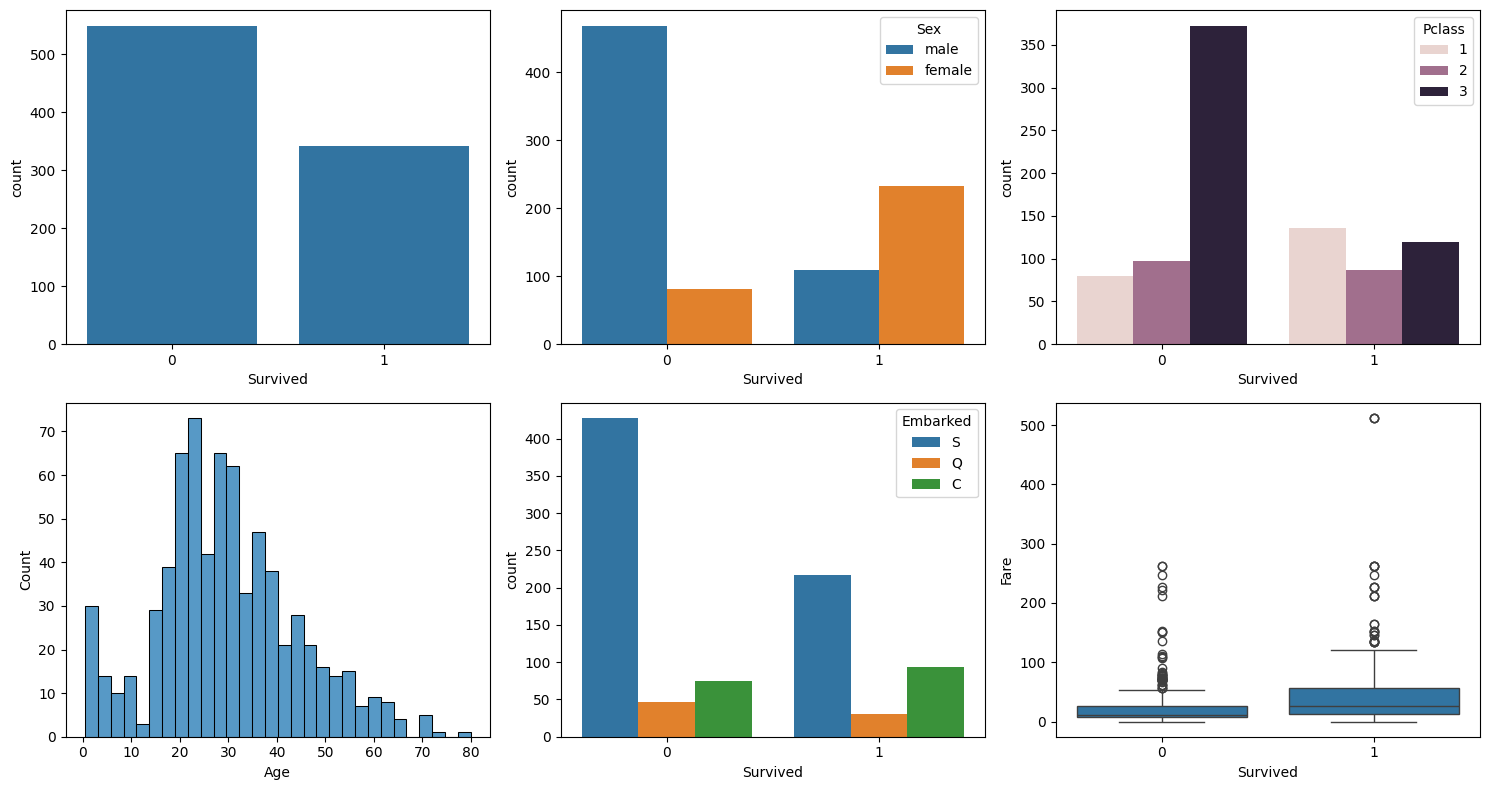

<Axes: >

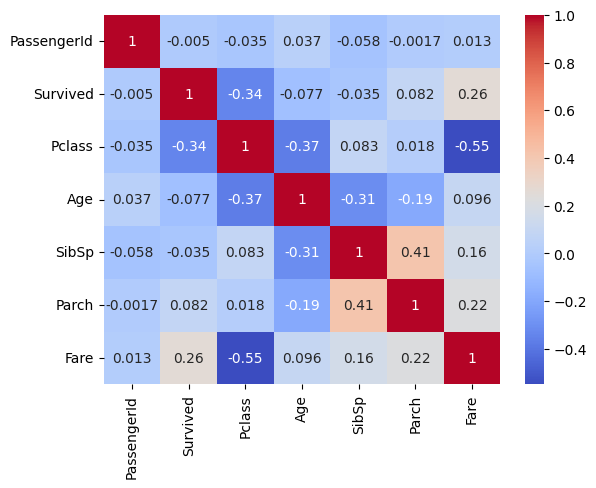

In [33]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sns.countplot(x='Survived', data=df, ax=axes[0,0])
sns.countplot(x='Survived', hue='Sex', data=df, ax=axes[0,1])
sns.countplot(x='Survived', hue='Pclass', data=df, ax=axes[0,2])
sns.histplot(df['Age'].dropna(), bins=30, ax=axes[1,0])
sns.countplot(x='Survived', hue='Embarked', data=df, ax=axes[1,1])
sns.boxplot(x='Survived', y='Fare', data=df, ax=axes[1,2])
plt.tight_layout()
plt.show()

# Correlation matrix (numeric only)
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')

In [34]:
# Title from name — surprisingly predictive
df['Title'] = df['Name'].str.extract(r',\s*([^\.]*)\s*\.')
df['Title'] = df['Title'].replace(['Lady','Countess','Capt','Col','Don','Dr',
    'Major','Rev','Sir','Jonkheer','Dona'], 'Rare')
df['Title'] = df['Title'].replace(['Mlle','Ms'], 'Miss')
df['Title'] = df['Title'].replace('Mme', 'Mrs')


In [35]:
# Family size
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)


In [36]:
# Has cabin info (instead of dropping the column outright)
df['HasCabin'] = df['Cabin'].notnull().astype(int)

In [37]:
# Fill missing Age smarter: median per (Pclass, Title) group instead of a single global median
df['Age'] = df.groupby(['Pclass', 'Title'])['Age'].transform(lambda x: x.fillna(x.median()))
df['Age'] = df['Age'].fillna(df['Age'].median())  # catch any remaining

In [38]:
# Fill missing Embarked with mode
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

In [39]:
# Fare has 1 missing in test set typically — fill defensively anyway
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

In [40]:
# Age and Fare bands (helps tree models, sometimes hurts linear ones — we'll test both ways)
df['AgeBand'] = pd.cut(df['Age'], 5, labels=False)
df['FareBand'] = pd.qcut(df['Fare'], 4, labels=False)

In [41]:
le = LabelEncoder()
for col in ['Sex', 'Embarked', 'Title']:
    df[col] = le.fit_transform(df[col])

features = ['Pclass','Sex','Age','SibSp','Parch','Fare','Embarked',
            'Title','FamilySize','IsAlone','HasCabin']
X = df[features]
y = df['Survived']

In [42]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [43]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(probability=True),
    'KNN': KNeighborsClassifier()
}

results = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    results[name] = scores.mean()
    print(f"{name}: {scores.mean():.4f} (+/- {scores.std():.4f})")

Logistic Regression: 0.8048 (+/- 0.0248)
Decision Tree: 0.7614 (+/- 0.0454)
Random Forest: 0.8063 (+/- 0.0337)
SVM: 0.6939 (+/- 0.0179)
KNN: 0.7290 (+/- 0.0354)


In [44]:
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [4, 6, 8, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)
best_model = grid.best_estimator_

{'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
0.8301585738205455


Accuracy: 0.8044692737430168
Precision: 0.765625
Recall: 0.7101449275362319
F1: 0.7368421052631579
ROC-AUC: 0.8555335968379447
              precision    recall  f1-score   support

           0       0.83      0.86      0.84       110
           1       0.77      0.71      0.74        69

    accuracy                           0.80       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.80      0.80      0.80       179



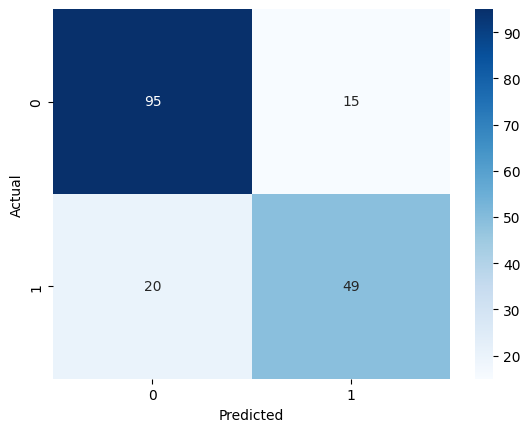

In [45]:
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()

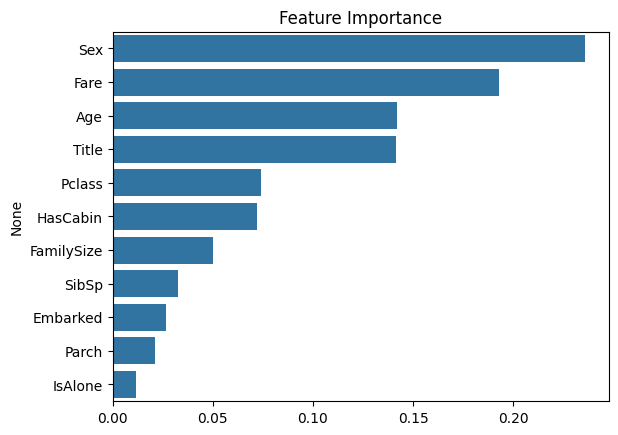

In [46]:
importances = pd.Series(best_model.feature_importances_, index=features).sort_values(ascending=False)
sns.barplot(x=importances.values, y=importances.index)
plt.title('Feature Importance');